# Lista 2: Inteligência Artificial (UFAL)
## Questão 12: Agente baseado em LLM com interface em linguagem natural, inferência e explicabilidade

**Dupla:**
- Bruno Gomes de Barros Filho, matrícula 21111360
- Antônio Rodrigo Lima de Andrade Tenório, matrícula 23210707

**Disciplina:** ECOM031: Inteligência Artificial
**Professor:** Evandro de Barros Costa
**Período:** 2026.2

---

### Enunciado (Q12)
> Especifique e desenvolva uma aplicação, de sua escolha, de sistema de agente baseado em LLM, incluindo
> componentes de interface de usuário em linguagem natural, inferência e explicabilidade.

**Aplicação escolhida:** um assistente de agenda acadêmica para professores, a partir do cenário da Q11.
Na Q11 concluímos que o LLM ajuda a interpretar pedidos em linguagem natural, mas que restrições,
planejamento e verificação precisam de mecanismos explícitos. Aqui implementamos essa divisão:

| Componente | Quem faz | Arquivo |
| :--- | :--- | :--- |
| Interface em linguagem natural | CLI de chat + LLM interpretando o pedido: Gemini (`gemini-3.5-flash-lite`, com `gemini-3.1-flash-lite` de reserva) ou Claude (`claude-opus-5-5`) | `agente_cli.py`, `agente.py`, `cliente_gemini.py` |
| Inferência / planejamento | Busca exata com poda (branch and bound), sem LLM | `planejador.py` |
| Verificação | Verificador de restrições independente da busca | `planejador.py` (`verificar`) |
| Explicabilidade | Justificativas estruturadas, contrafactuais, trace de ferramentas | `explicacao.py`, `agente.py` |

O notebook roda sem chave de API. Nas seções 6.1 e 6.2 o LLM é substituído por um cliente roteirizado,
identificado como simulação sempre que aparece. A seção 6.3 chama o Gemini de verdade quando a chave
`GEMINI_API_KEY` está no ambiente ou no arquivo `.env` da raiz do repositório (que não vai para o git).
O planejador, o verificador e as explicações são executados de verdade em todas as células.


---
## 0. Imports

In [1]:
import json
import os
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from agente import Agente, ClienteAnthropic, FERRAMENTAS, MODELO
from agente_cli import carregar_env
from cliente_gemini import MODELO_PRINCIPAL, MODELO_RESERVA, ClienteGemini
from explicacao import avaliar_proposta, explicar, texto_explicacao
from gantt import desenhar_gantt
from planejador import Atividade, Segmento, hhmm_para_min as h, planejar, urgencia
from simulacao import PEDIDO_NOVO, PEDIDO_Q11, ClienteRoteirizado, roteiro_q11

FIG = Path('figures')
FIG.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth', 120)
plt.rcParams.update({'figure.dpi': 110, 'figure.facecolor': '#fcfcfb'})
carregar_env()  # lê GEMINI_API_KEY do .env da raiz, se existir; a chave nunca é impressa
print('Gemini:', MODELO_PRINCIPAL, '(principal) e', MODELO_RESERVA, '(reserva). Claude:', MODELO)

Gemini: gemini-3.5-flash-lite (principal) e gemini-3.1-flash-lite (reserva). Claude: claude-opus-5-5


---
## 1. Modelo do problema e função de utilidade

Cada atividade tem duração, prioridade, prazo (em dias a partir de hoje), e opcionalmente horário fixo,
prazo com horário e permissão para ser dividida. A utilidade de um plano é

$$U = \sum_a \text{peso}(\text{prioridade}_a)\cdot \text{urg}(\text{prazo}_a)\cdot \frac{\text{minutos feitos}_a}{\text{duração}_a},
\qquad \text{urg}(d) = 1 + \frac{2}{1+d}$$

com pesos alta = 3, média = 2 e baixa = 1. A urgência vale 3 para hoje, 2 para amanhã e 1,25 para daqui a
uma semana. A fração final é o $f(B)$ da função de utilidade da Q11: uma atividade divisível feita pela
metade rende metade do seu valor; uma não divisível rende tudo ou nada.

As restrições rígidas vêm direto do enunciado da Q11: janela disponível, compromissos fixos no horário
marcado, nenhuma sobreposição, atividade iniciada vai até o fim (a menos que o professor permita dividir)
e prazos com horário cumpridos.

In [2]:
def cenario_q11(b_divisivel=False):
    return [
        Atividade('A', 'Preparar aula de IA', 90, 'alta', 0),
        Atividade('B', 'Corrigir trabalhos', 120, 'media', 1, divisivel=b_divisivel),
        Atividade('C', 'Reunião de pesquisa', 60, 'alta', 0, inicio_fixo=h('16:00')),
        Atividade('D', 'Revisar artigo', 60, 'baixa', 7),
    ]

pd.DataFrame([{
    'id': a.id, 'atividade': a.nome, 'duração (min)': a.duracao, 'prioridade': a.prioridade,
    'prazo (dias)': a.prazo_dias, 'urgência': urgencia(a.prazo_dias), 'valor': a.valor,
    'valor por hora': round(60 * a.valor / a.duracao, 2), 'fixa': a.fixa,
} for a in cenario_q11()])

,id,atividade,duração (min),prioridade,prazo (dias),urgência,valor,valor por hora,fixa
0,A,Preparar aula de IA,90,alta,0,3.00,9.00,6.00,False
1,B,Corrigir trabalhos,120,media,1,2.00,4.00,2.00,False
2,C,Reunião de pesquisa,60,alta,0,3.00,9.00,9.00,True
3,D,Revisar artigo,60,baixa,7,1.25,1.25,1.25,False


---
## 2. Cenário da Q11: plano ótimo para 14h-18h

Primeiro o caso do enunciado sem divisão de atividades. O planejador recebe os dados já estruturados
(na seção 6 eles chegam pelo agente, a partir do texto livre).

In [3]:
base = explicar(cenario_q11(), h('14:00'), h('18:00'))
print(texto_explicacao(base))

Plano para 14:00-18:00 (utilidade 19,25; 23,25 se tudo coubesse):
  14:00-15:30  A  Preparar aula de IA
  16:00-17:00  C  Reunião de pesquisa
  17:00-18:00  D  Revisar artigo
Por que algo ficou de fora ou incompleto:
  - B (Corrigir trabalhos): exigir B levaria a utilidade a 14,25 (perda de 5,00), com as trocas A 90->0 min, B 0->120 min.
Tempo livre não usado 15:30-16:00 (30 min): B precisa de 120 min contínuos.
Segunda melhor alternativa: forçar B dá utilidade 14,25, 5,00 abaixo do plano escolhido.
Verificador independente: nenhuma violação.


In [4]:
pd.DataFrame(base['plano'])

,atividade,nome,inicio,fim,minutos
0,A,Preparar aula de IA,14:00,15:30,90
1,C,Reunião de pesquisa,16:00,17:00,60
2,D,Revisar artigo,17:00,18:00,60


A explicação acima foi montada só com os campos do resumo estruturado. O mesmo resumo é o que o agente
devolve ao LLM como resultado da ferramenta `planejar_agenda`. Abaixo estão as justificativas por atividade
e as restrições que o planejador registrou como ativas.

In [5]:
for d in base['atividades']:
    print(f"{d['id']} ({d['status']}, contribui {d['contribuicao']}):")
    for j in d['justificativa']:
        print('   -', j)
    if d['contrafactual']:
        print('   - contrafactual:', json.dumps({k: v for k, v in d['contrafactual'].items() if k != 'segmentos'},
                                                 ensure_ascii=False))
print()
print('Restrições ativas:')
for r in base['restricoes_ativas']:
    print('   -', r)

A (completa, contribui 9.0):
   - valor 9,00 = peso 3 (prioridade alta) x urgência 3,00 (prazo em 0 dia(s))
   - bloco 14:00-15:30 (90 min), logo após o início da janela
B (fora, contribui 0.0):
   - valor 4,00 = peso 2 (prioridade media) x urgência 2,00 (prazo em 1 dia(s))
   - contrafactual: {"pergunta": "e se B recebesse pelo menos 120 min?", "viavel": true, "utilidade": 14.25, "perda": 5.0, "mudancas": [{"atividade": "A", "minutos_antes": 90, "minutos_depois": 0}, {"atividade": "B", "minutos_antes": 0, "minutos_depois": 120}]}
C (fixa, contribui 9.0):
   - valor 9,00 = peso 3 (prioridade alta) x urgência 3,00 (prazo em 0 dia(s))
   - compromisso fixo 16:00-17:00, tratado como restrição rígida
D (completa, contribui 1.25):
   - valor 1,25 = peso 1 (prioridade baixa) x urgência 1,25 (prazo em 7 dia(s))
   - bloco 17:00-18:00 (60 min), logo após o fim de C; termina no fim da janela

Restrições ativas:
   - janela 14:00-18:00 (240 min)
   - compromisso fixo C em 16:00-17:00
   - interv

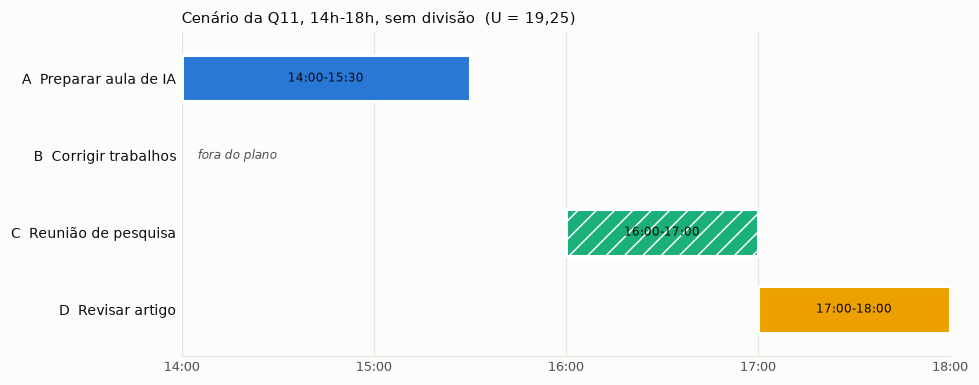

In [6]:
ax = desenhar_gantt(base, 'Cenário da Q11, 14h-18h, sem divisão', caminho=FIG / 'q12_gantt_q11.png')
ax.figure.savefig(FIG / 'q12_gantt_q11.pdf', bbox_inches='tight')
plt.show()

O plano coloca a aula (A) às 14h, mantém a reunião (C) às 16h e usa 17h-18h para a revisão do artigo (D).
A correção (B) fica de fora: ela precisa de 120 minutos contínuos e o único intervalo com esse tamanho,
14h-16h, também é o único onde cabe a aula. Exigir B tira A do plano e derruba a utilidade de 19,25 para
14,25. Os 30 minutos entre 15h30 e 16h ficam ociosos porque nenhuma atividade restante cabe neles.

Há uma diferença em relação ao plano feito à mão na Q11. Lá, no caso sem divisão, a revisão do artigo
foi adiada por ter prioridade baixa. O planejador encontrou que ela cabe exatamente no horário 17h-18h
e soma 1,25 de utilidade sem prejudicar nenhuma outra atividade. A seção 5 confere isso com o verificador.

---
## 3. A busca: por que exata e quanto custa

O planejador faz busca em profundidade sobre agendas justificadas à esquerda: a cada instante livre ele
começa uma atividade, executa um bloco de uma atividade divisível (em passos de 15 min) ou fica ocioso até
o próximo compromisso fixo. Ficar ocioso e começar algo depois, antes do próximo compromisso, nunca é
necessário, porque qualquer agenda viável pode ser deslocada para a esquerda sem violar restrição.

A poda usa a relaxação fracionária do tempo livre restante (mochila fracionária) como limite superior.
No cenário da Q11 o espaço é pequeno; a tabela mostra o número de nós com e sem poda e um caso maior,
com oito atividades, para dar uma ideia do crescimento.

In [7]:
import random, time
from test_q12_planejador import instancia_aleatoria

def medir(nome, ativs, inicio, fim, passo=15, podas=(True, False)):
    linhas = []
    for podar in podas:
        t0 = time.perf_counter()
        r = planejar(ativs, inicio, fim, passo=passo, podar=podar)
        linhas.append({'instância': nome, 'poda': podar, 'utilidade': round(r.melhor.utilidade, 4),
                       'nós explorados': r.estatisticas['nos_explorados'],
                       'planos completos': r.estatisticas['planos_completos'],
                       'tempo (s)': round(time.perf_counter() - t0, 3)})
    return linhas

pd.DataFrame(medir('Q11, sem divisão', cenario_q11(), h('14:00'), h('18:00'))
             + medir('Q11, B divisível', cenario_q11(True), h('14:00'), h('18:00')))

,instância,poda,utilidade,nós explorados,planos completos,tempo (s)
0,"Q11, sem divisão",True,19.25,13,2,0.000
1,"Q11, sem divisão",False,19.25,18,7,0.000
2,"Q11, B divisível",True,21.00,47,10,0.000
3,"Q11, B divisível",False,21.00,162,78,0.001


Para ver o crescimento, a célula abaixo gera instâncias aleatórias numa janela de 8 horas (passo de
30 min, cerca de 40% das atividades divisíveis) e mede a busca com poda para 4 a 7 atividades.

In [8]:
linhas = []
for n in (4, 5, 6, 7):
    ativs, ini, fim_ = instancia_aleatoria(random.Random(1000 * n), n_slots=16, n_ativ=n)
    linhas += medir(f'{n} atividades, 8 h', ativs, ini, fim_, passo=30, podas=(True,))
pd.DataFrame(linhas)

,instância,poda,utilidade,nós explorados,planos completos,tempo (s)
0,"4 atividades, 8 h",True,14.75,34,16,0.000
1,"5 atividades, 8 h",True,18.25,3702,1851,0.026
2,"6 atividades, 8 h",True,18.50,3862,1937,0.027
3,"7 atividades, 8 h",True,36.00,1398436,714032,7.702


No cenário da Q11 a busca visita algumas dezenas de nós e a poda corta boa parte deles. Até seis
atividades o tempo fica abaixo de um décimo de segundo. A partir de sete, com várias atividades divisíveis,
o número de nós passa de um milhão e o tempo vai para a casa dos segundos; em testes fora do notebook,
oito atividades levaram cerca de um minuto. O crescimento vem principalmente das muitas formas de fatiar
atividades divisíveis em agendas de mesma utilidade, que a poda (só corta ramos estritamente piores)
não elimina. Para a agenda de um dia típico isso basta, e com busca exata o plano anunciado é o ótimo
da função de utilidade declarada. Para agendas maiores, o caminho seria programação dinâmica sobre o
estado (instante, minutos feitos por atividade) ou um resolvedor de restrições como o CP-SAT.

O arquivo `test_q12_planejador.py` confere a busca de três formas: em 120 instâncias pequenas o ótimo é
igual ao de uma força bruta que testa toda atribuição de horários e filtra pelo verificador; em 200
instâncias maiores a busca com poda dá a mesma utilidade que a busca sem poda; e em 60 instâncias o plano
devolvido passa no verificador.

---
## 4. Variações do cenário

1. A correção (B) pode ser dividida em blocos de pelo menos 30 minutos.
2. A janela vai até 19h (cinco horas), sem divisão.

In [9]:
variacoes = {
    'Q11 (14h-18h, sem divisão)': base,
    'B divisível (14h-18h)': explicar(cenario_q11(True), h('14:00'), h('18:00')),
    'Janela de 5 h (14h-19h)': explicar(cenario_q11(), h('14:00'), h('19:00')),
}
linhas = []
for nome, r in variacoes.items():
    alt = r['segunda_melhor_alternativa']
    linhas.append({
        'cenário': nome,
        'plano': ', '.join(f"{p['atividade']} {p['inicio']}-{p['fim']}" for p in r['plano']),
        'U': r['utilidade'],
        'fora/parcial': ', '.join(f"{d['id']} ({d['minutos']}/{d['duracao']})" for d in r['atividades']
                                  if d['status'] in ('fora', 'parcial')),
        '2ª alternativa': f"forçar {alt['forcando']}: U={alt['utilidade']}" if alt else '-',
        'válido': r['verificacao']['valido'],
    })
pd.DataFrame(linhas)

,cenário,plano,U,fora/parcial,2ª alternativa,válido
0,"Q11 (14h-18h, sem divisão)","A 14:00-15:30, C 16:00-17:00, D 17:00-18:00",19.25,B (0/120),forçar B: U=14.25,True
1,B divisível (14h-18h),"A 14:00-15:30, B 15:30-16:00, C 16:00-17:00, B 17:00-18:00",21.00,"B (90/120), D (0/60)",forçar D: U=20.25,True
2,Janela de 5 h (14h-19h),"A 14:00-15:30, C 16:00-17:00, B 17:00-19:00",22.00,D (0/60),forçar D: U=19.25,True


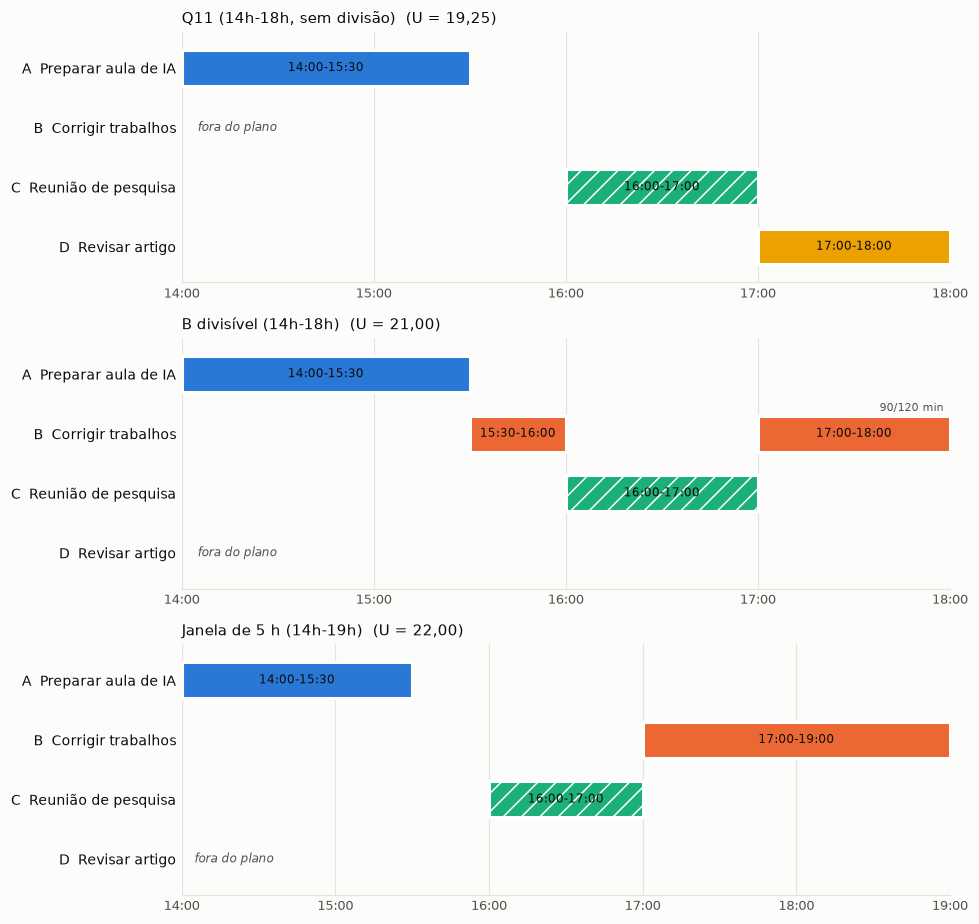

In [10]:
fig, eixos = plt.subplots(3, 1, figsize=(9, 8.5))
for ax, (nome, r) in zip(eixos, variacoes.items()):
    desenhar_gantt(r, nome, ax=ax)
fig.tight_layout()
fig.savefig(FIG / 'q12_gantt_variacoes.png', dpi=150, bbox_inches='tight')
fig.savefig(FIG / 'q12_gantt_variacoes.pdf', bbox_inches='tight')
plt.show()

In [11]:
print(texto_explicacao(variacoes['B divisível (14h-18h)']))
print()
print(texto_explicacao(variacoes['Janela de 5 h (14h-19h)']))

Plano para 14:00-18:00 (utilidade 21,00; 23,25 se tudo coubesse):
  14:00-15:30  A  Preparar aula de IA
  15:30-16:00  B  Corrigir trabalhos
  16:00-17:00  C  Reunião de pesquisa
  17:00-18:00  B  Corrigir trabalhos
B (Corrigir trabalhos) foi dividida: 90 de 120 min hoje, o restante fica para depois.
Por que algo ficou de fora ou incompleto:
  - B (Corrigir trabalhos): exigir B levaria a utilidade a 14,25 (perda de 6,75), com as trocas A 90->0 min, B 90->120 min, D 0->60 min.
  - D (Revisar artigo): exigir D levaria a utilidade a 20,25 (perda de 0,75), com as trocas B 90->30 min, D 0->60 min.
Segunda melhor alternativa: forçar D dá utilidade 20,25, 0,75 abaixo do plano escolhido.
Verificador independente: nenhuma violação.

Plano para 14:00-19:00 (utilidade 22,00; 23,25 se tudo coubesse):
  14:00-15:30  A  Preparar aula de IA
  16:00-17:00  C  Reunião de pesquisa
  17:00-19:00  B  Corrigir trabalhos
Por que algo ficou de fora ou incompleto:
  - D (Revisar artigo): exigir D levaria a ut

Com B divisível, o planejador aproveita os 30 minutos antes da reunião e a hora depois dela para a
correção: 90 dos 120 minutos ficam feitos hoje e a revisão do artigo sai do plano. A troca vale a pena
porque B rende 2 de utilidade por hora e D rende 1,25. A segunda melhor alternativa (forçar D) perde
só 0,75, o que mostra que a escolha depende bastante dos pesos: com prazo de B mais distante, a
decisão poderia se inverter.

Com a janela até 19h, B cabe inteira em 17h-19h e passa na frente de D. A revisão fica de fora porque
o único intervalo livre restante (15h30-16h) tem só 30 minutos.

---
## 5. Verificador independente

O verificador não reaproveita nada da busca. Ele recebe uma lista de blocos e confere cada restrição.
Serve para validar o próprio planejador e qualquer plano vindo de fora, inclusive um plano que o LLM
tente propor sozinho. Abaixo, três propostas no cenário da Q11:

- o plano manual da Q11 para o caso sem divisão (A, C e nada depois das 17h);
- o plano manual da Q11 para o caso com divisão (B só em 17h-18h);
- um plano que um modelo de linguagem sem ferramentas poderia escrever, com B das 14h às 16h e a aula
  logo depois da correção, por cima da reunião.

In [12]:
def blocos(*trios):
    return [Segmento(i, h(a), h(b)) for i, a, b in trios]

propostas = {
    'Q11 manual, sem divisão': (cenario_q11(), blocos(('A', '14:00', '15:30'), ('C', '16:00', '17:00'))),
    'Q11 manual, B dividida': (cenario_q11(True), blocos(('A', '14:00', '15:30'), ('C', '16:00', '17:00'),
                                                          ('B', '17:00', '18:00'))),
    'Plano com conflito': (cenario_q11(), blocos(('B', '14:00', '16:00'), ('A', '16:00', '17:30'),
                                                 ('C', '16:00', '17:00'))),
}
linhas = []
for nome, (ativs, segs) in propostas.items():
    r = avaliar_proposta(segs, ativs, h('14:00'), h('18:00'))
    linhas.append({'proposta': nome, 'válida': r['valido'], 'U proposta': r['utilidade_proposta'],
                   'U ótima': r['utilidade_otima'], 'violações': '; '.join(r['violacoes']) or '-',
                   'diferença para o ótimo': ', '.join(f"{m['atividade']} {m['minutos_antes']}->{m['minutos_depois']}"
                                                       for m in r['diferenca_para_otimo'])})
pd.DataFrame(linhas)

,proposta,válida,U proposta,U ótima,violações,diferença para o ótimo
0,"Q11 manual, sem divisão",True,18.0,19.25,-,D 60->0
1,"Q11 manual, B dividida",True,20.0,21.00,-,B 90->60
2,Plano com conflito,False,NaN,19.25,sobreposição entre C (16:00-17:00) e A (16:00-17:30),"B 0->120, D 60->0"


Os dois planos manuais da Q11 são válidos, mas ficam abaixo do ótimo: 18,0 contra 19,25 sem divisão
(D cabia em 17h-18h) e 20,0 contra 21,0 com divisão (os 30 minutos antes da reunião podiam adiantar B).
O terceiro plano é rejeitado com a sobreposição apontada e a reunião deslocada. É esse tipo de erro que
a Q11 atribui a um LLM sem verificação.

---
## 6. O agente: linguagem natural, ferramentas e explicação

O agente (`agente.py`) roda um loop manual de uso de ferramentas com a Messages API. O LLM tem cinco
ferramentas, todas com `strict: true` e schemas com `additionalProperties: false`:

In [13]:
for f in FERRAMENTAS:
    print(f"- {f['name']}: {f['description']}")

- definir_janela: Define o intervalo de tempo disponível hoje (HH:MM a HH:MM). Substitui a janela anterior.
- registrar_atividades: Inclui ou atualiza atividades na agenda (atualiza quando o id já existe). Devolve a agenda atual com o valor calculado de cada atividade.
- remover_atividade: Remove uma atividade da agenda pelo id.
- planejar_agenda: Calcula o plano de maior utilidade para a agenda atual com busca exata e devolve justificativas: motivo de cada horário, motivo de cada atividade fora do plano, restrições ativas, segunda melhor alternativa e verificação independente.
- avaliar_plano: Verifica um plano proposto pelo professor (ou por você) contra as restrições e compara sua utilidade com a do plano ótimo.


### 6.1 Simulação roteirizada (sem chave de API)

**Atenção:** nesta seção não há LLM. O cliente `ClienteRoteirizado` devolve mensagens com o mesmo formato
das respostas da API (`BetaMessage` com blocos `tool_use` e `text`), mas as chamadas de ferramenta foram
escritas à mão no roteiro, representando o que esperamos que o LLM extraia do pedido. O texto final de
cada turno é a explicação determinística do planejador (`texto_explicacao`), não um texto gerado por
modelo. O que é real aqui: o loop do agente, a execução das ferramentas, os `tool_result` devolvidos,
o planejador, o verificador e o histórico multi-turno.

A conversa tem dois turnos. No primeiro, o professor faz o pedido da Q11 em texto livre. No segundo,
surge uma orientação de TCC de 30 minutos, de prioridade alta, para hoje, e o agente precisa replanejar.

In [14]:
cliente_sim = ClienteRoteirizado(roteiro_q11())
agente_sim = Agente(cliente_sim)

def mostrar_turno(pedido, resposta):
    print('PROFESSOR:', pedido)
    print()
    print('TRACE DE FERRAMENTAS:')
    for c in resposta.trace:
        print(f"  {c.nome}  erro={c.erro}  entrada={json.dumps(c.entrada, ensure_ascii=False)[:110]}")
    print()
    print('RESPOSTA (explicação determinística, simulação):')
    print(resposta.texto)

turno1 = agente_sim.processar(PEDIDO_Q11)
mostrar_turno(PEDIDO_Q11, turno1)

PROFESSOR: Preciso preparar uma aula de Inteligência Artificial, corrigir trabalhos de alunos e participar de uma reunião de pesquisa. Tenho apenas quatro horas disponíveis hoje, das 14h às 18h. A preparação da aula é urgente e leva uns 90 minutos. A correção dos trabalhos precisa ser concluída até amanhã e leva duas horas. A reunião é das 16h às 17h. Também tenho a revisão de um artigo, uma hora de trabalho, para a próxima semana, mas é a menos importante. Organize minhas atividades da melhor maneira possível.

TRACE DE FERRAMENTAS:
  definir_janela  erro=False  entrada={"inicio": "14:00", "fim": "18:00"}
  registrar_atividades  erro=False  entrada={"atividades": [{"id": "A", "nome": "Preparar aula de IA", "duracao_min": 90, "prioridade": "alta", "prazo_dia
  planejar_agenda  erro=False  entrada={}

RESPOSTA (explicação determinística, simulação):
Plano para 14:00-18:00 (utilidade 19,25; 23,25 se tudo coubesse):
  14:00-15:30  A  Preparar aula de IA
  16:00-17:00  C  Reunião de pesqui

In [15]:
turno2 = agente_sim.processar(PEDIDO_NOVO)
mostrar_turno(PEDIDO_NOVO, turno2)

PROFESSOR: Surgiu agora uma orientação de TCC de 30 minutos, alta prioridade, tem que ser hoje. Encaixe na agenda.

TRACE DE FERRAMENTAS:
  registrar_atividades  erro=False  entrada={"atividades": [{"id": "E", "nome": "Orientação de TCC", "duracao_min": 30, "prioridade": "alta", "prazo_dias"
  planejar_agenda  erro=False  entrada={}

RESPOSTA (explicação determinística, simulação):
Plano para 14:00-18:00 (utilidade 28,25; 32,25 se tudo coubesse):
  14:00-14:30  E  Orientação de TCC
  14:30-16:00  A  Preparar aula de IA
  16:00-17:00  C  Reunião de pesquisa
  17:00-18:00  D  Revisar artigo
Por que algo ficou de fora ou incompleto:
  - B (Corrigir trabalhos): exigir B levaria a utilidade a 22,00 (perda de 6,25), com as trocas A 90->0 min, B 0->120 min, D 60->0 min.
Segunda melhor alternativa: forçar B dá utilidade 22,00, 6,25 abaixo do plano escolhido.
Verificador independente: nenhuma violação.


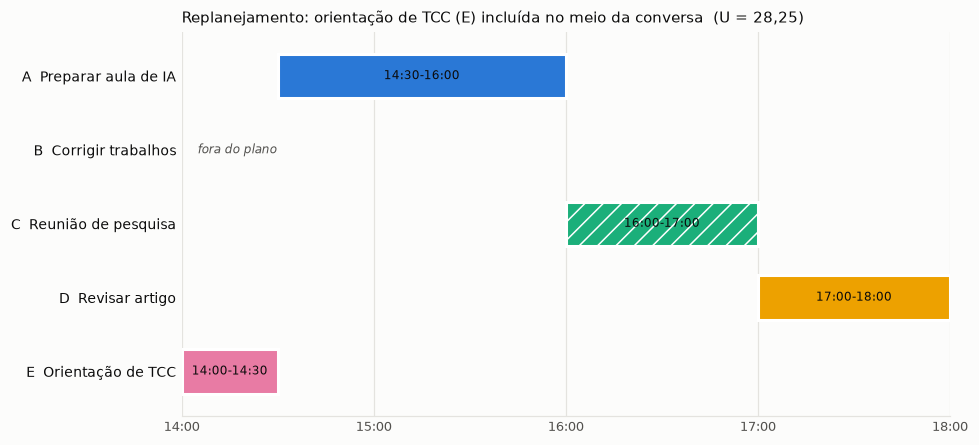

In [16]:
ax = desenhar_gantt(turno2.resumo, 'Replanejamento: orientação de TCC (E) incluída no meio da conversa',
                    caminho=FIG / 'q12_gantt_replanejamento.png')
ax.figure.savefig(FIG / 'q12_gantt_replanejamento.pdf', bbox_inches='tight')
plt.show()

A orientação de TCC (E, valor 9) entra às 14h. A aula passa para 14h30-16h e o intervalo ocioso de
15h30-16h desaparece. Como E e A têm o mesmo valor, as duas ordens dão a mesma utilidade; o critério de
desempate do planejador termina primeiro a atividade que acaba antes quando os valores empatam (soma de
valor x horário de término menor). O restante do plano não muda.

A célula abaixo mostra o histórico que seria enviado à API no segundo turno. Cada resposta do assistente
entra inteira (todos os blocos, não só o texto) e cada grupo de `tool_result` vai numa única mensagem de
usuário, com o `tool_use_id` da chamada correspondente.

In [17]:
for i, m in enumerate(agente_sim.historico):
    if isinstance(m['content'], str):
        desc = 'texto: ' + m['content'][:70] + '...'
    elif m['role'] == 'assistant':
        desc = ', '.join(f"{b.type}({b.name})" if b.type == 'tool_use' else b.type for b in m['content'])
    else:
        desc = ', '.join(f"tool_result(id={r['tool_use_id']}, is_error={r['is_error']})" for r in m['content'])
    print(f"{i:2d} {m['role']:9s} {desc}")

 0 user      texto: Preciso preparar uma aula de Inteligência Artificial, corrigir trabalh...
 1 assistant tool_use(definir_janela), tool_use(registrar_atividades)
 2 user      tool_result(id=toolu_sim_0001, is_error=False), tool_result(id=toolu_sim_0002, is_error=False)
 3 assistant tool_use(planejar_agenda)
 4 user      tool_result(id=toolu_sim_0004, is_error=False)
 5 assistant text
 6 user      texto: Surgiu agora uma orientação de TCC de 30 minutos, alta prioridade, tem...
 7 assistant tool_use(registrar_atividades)
 8 user      tool_result(id=toolu_sim_0006, is_error=False)
 9 assistant tool_use(planejar_agenda)
10 user      tool_result(id=toolu_sim_0008, is_error=False)
11 assistant text


### 6.2 Tratamento de erro de ferramenta

Se o LLM mandar um horário inválido, a ferramenta levanta erro e o agente devolve um `tool_result` com
`is_error: true` e a mensagem. O modelo pode então corrigir a chamada ou explicar o problema. De novo,
as respostas do assistente abaixo são roteirizadas.

In [18]:
from simulacao import chamada, mensagem, texto

cliente_erro = ClienteRoteirizado([
    mensagem(chamada('definir_janela', {'inicio': '14h', 'fim': '18:00'})),
    mensagem(chamada('definir_janela', {'inicio': '14:00', 'fim': '18:00'})),
    mensagem(texto('Janela registrada: 14:00-18:00.')),
])
resposta = Agente(cliente_erro).processar('Estou livre das 14h às 18h.')
for c in resposta.trace:
    print(f"{c.nome}({c.entrada}) -> is_error={c.erro}: {c.resultado}")

definir_janela({'inicio': '14h', 'fim': '18:00'}) -> is_error=True: Erro: horário inválido: '14h' (use HH:MM)
definir_janela({'inicio': '14:00', 'fim': '18:00'}) -> is_error=False: {"janela": {"inicio": "14:00", "fim": "18:00"}}


### 6.3 Execução com um LLM de verdade (Gemini)

A célula abaixo só chama a API se `GEMINI_API_KEY` estiver definida. Ela usa o mesmo `Agente` da simulação,
agora com `ClienteGemini`: o modelo principal é `gemini-3.5-flash-lite` e, se ele estiver indisponível ou sem
cota (erros 404, 429 ou 5xx), a mesma requisição vai para `gemini-3.1-flash-lite`. O cliente traduz o
histórico do agente para o formato do Gemini e devolve as respostas no formato de blocos que o loop espera,
então ferramentas, planejador e verificador são exatamente os mesmos. A conversa tem os mesmos dois turnos da
simulação: o pedido da Q11 e, depois, a orientação de TCC.

As saídas abaixo são do modelo de verdade e mudam a cada execução. Os fatos do plano (horários, utilidade,
o que ficou de fora) vêm sempre do planejador; o texto em volta é do modelo.

### professor> Preciso preparar uma aula de Inteligência Artificial, corrigir trabalhos de alunos e parti...
(modelo que respondeu: gemini-3.5-flash-lite)
[ferramenta] definir_janela erro=False entrada={"inicio": "14:00", "fim": "18:00"}
[ferramenta] registrar_atividades erro=False entrada={"atividades": [{"bloco_minimo_min": null, "prazo_dias": 0, "id": "aula_ia", "divisivel": false, "duracao_min": 90, "prazo_hora": null, "prioridade": 
[ferramenta] planejar_agenda erro=False entrada={}

Organizei a sua agenda com base na janela disponível das 14h às 18h e nas atividades informadas.

### Plano de Atividades

| Horário | Atividade |
| :--- | :--- |
| 14:00 – 15:30 | Preparar aula de Inteligência Artificial |
| 15:30 – 16:00 | *Intervalo ocioso* (30 minutos, pois não há tempo contínuo suficiente para a correção de trabalhos neste bloco) |
| 16:00 – 17:00 | Reunião de pesquisa |
| 17:00 – 18:00 | Revisão de um artigo |

---

### Atividades Fora do Plano
* **Corrigir trabalhos de alunos**

### professor> Surgiu agora uma orientação de TCC de 30 minutos, alta prioridade, tem que ser hoje. Encai...
(modelo que respondeu: gemini-3.5-flash-lite)
[ferramenta] registrar_atividades erro=False entrada={"atividades": [{"id": "aula_ia", "nome": "Preparar aula de Inteligência Artificial", "duracao_min": 90, "divisivel": false, "prioridade": "alta", "pr
[ferramenta] planejar_agenda erro=False entrada={}

Atualizei a sua agenda para incluir a nova orientação de TCC. Veja como ficou a organização:

### Plano de Atividades

| Horário | Atividade |
| :--- | :--- |
| 14:00 – 14:30 | Orientação de TCC |
| 14:30 – 16:00 | Preparar aula de Inteligência Artificial |
| 16:00 – 17:00 | Reunião de pesquisa |
| 17:00 – 18:00 | Revisão de um artigo |

---

### Atividades Fora do Plano
* **Corrigir trabalhos de alunos**: Permaneceu de fora porque exige 120 minutos contínuos e o tempo restante na janela (mesmo com a adição da orientação) não é suficiente para acomodá-la sem excluir outras atividade

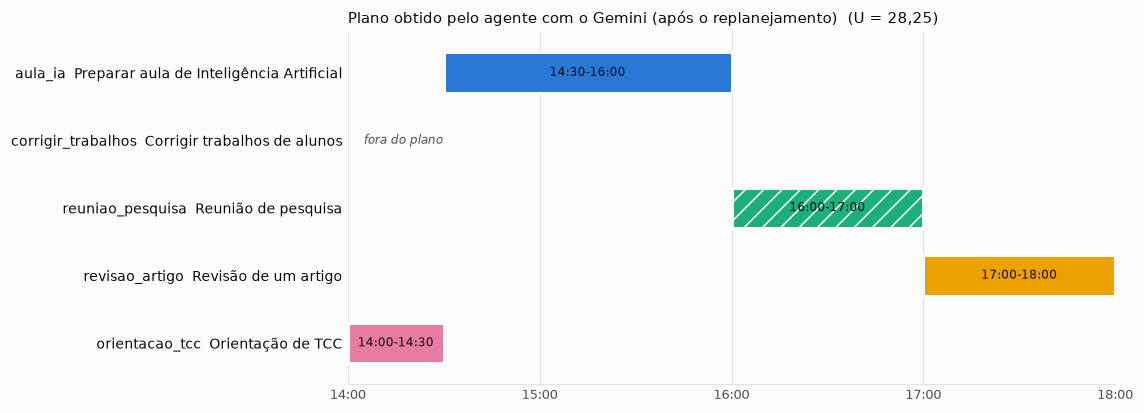

In [19]:
if os.environ.get('GEMINI_API_KEY'):
    cliente_real = ClienteGemini()
    agente_real = Agente(cliente_real)
    for pedido in (PEDIDO_Q11, PEDIDO_NOVO):
        resposta_real = agente_real.processar(pedido)
        print(f'### professor> {pedido[:90]}...')
        print(f'(modelo que respondeu: {cliente_real.modelo_usado})')
        for c in resposta_real.trace:
            print(f"[ferramenta] {c.nome} erro={c.erro} entrada={json.dumps(c.entrada, ensure_ascii=False)[:150]}")
        print()
        print(resposta_real.texto)
        print()
    if resposta_real.resumo:
        desenhar_gantt(resposta_real.resumo, 'Plano obtido pelo agente com o Gemini (após o replanejamento)')
        plt.show()
else:
    print('GEMINI_API_KEY não definida: a chamada real ao LLM foi pulada.')

---
## 7. Resumo dos resultados

| Cenário | Plano ótimo | U | Fica de fora |
| :--- | :--- | :---: | :--- |
| Q11, 14h-18h, sem divisão | A 14:00-15:30, C 16:00-17:00, D 17:00-18:00 | 19,25 | B (precisa de 120 min contínuos) |
| B divisível (blocos de 30 min) | A 14:00-15:30, B 15:30-16:00, C 16:00-17:00, B 17:00-18:00 | 21,00 | B parcial (90/120), D |
| Janela 14h-19h | A 14:00-15:30, C 16:00-17:00, B 17:00-19:00 | 22,00 | D |
| Pedido novo (E, 30 min, alta, hoje) | E 14:00-14:30, A 14:30-16:00, C 16:00-17:00, D 17:00-18:00 | 28,25 | B |

- O LLM fica com a parte que a Q11 apontou como seu ponto forte: entender o pedido em texto livre e
  redigir a resposta. Horários, utilidades e motivos saem das ferramentas.
- A busca exata é viável no tamanho de um dia de trabalho (dezenas de nós no cenário da Q11, menos de
  0,1 s até seis atividades) e permite afirmar que o plano é ótimo para a utilidade declarada, além de
  calcular contrafactuais ("e se B fosse feita?"). Com sete ou mais atividades divisíveis ela fica lenta.
- O verificador independente pegou as violações de um plano com conflito e mostrou que os planos manuais
  da Q11 eram válidos, mas deixavam utilidade para trás.
- A qualidade do plano continua dependendo da função de utilidade. Os pesos são uma escolha nossa e a
  seção 4 mostra decisões que mudam com pequenas alterações neles.